# Phân Khúc Khách Hàng Bằng Mô Hình RFM (RFM Customer Segmentation)
**Dự án:** Phân tích Giữ chân Khách hàng (Customer Retention & RFM Analysis)  
**Tập dữ liệu đầu vào:**
* `data/processed/online_retail_clean.parquet` (391.152 dòng, 4.334 khách hàng, £8.568.758,04)
* `data/processed/returns_clean.parquet` (8.505 dòng, 1.533 khách hàng, -£303.281,11)

**Mục tiêu phân tích:**
1. Trích xuất 3 chỉ số hành vi cốt lõi: **Recency ($R$)**, **Frequency ($F$)**, và **Monetary ($M$ - Matched Net Spend)**.
2. Xử lý chuẩn xác **10 khách hàng Zero Net Spend** (mua rồi hủy sạch 100%, kiểm soát sai số dấu phẩy động |net| < £0.005) vào phân khúc riêng, giữ nguyên **4.324 khách hàng hoạt động** cho ma trận RFM.
3. Chấm điểm phân vị khoa học (Quintiles cho $R$ và $M$; Custom Domain Cut cho $F$ để tránh lỗi phân vị trùng giá trị `pd.qcut`).
4. Áp dụng **Ma trận 5×5 (25 ô tổ hợp)** đã kiểm định: bao phủ 100% khách hàng hoạt động, không trùng lặp, không bỏ sót (gồm ô $(3,1)$ và $(3,2)$ thuộc phân khúc *Promising*).
5. Phân tích hồ sơ đặc trưng từng phân khúc (Segment Profile), vẽ biểu đồ ma trận và độ lệch doanh thu Pareto.
6. Xuất bảng dữ liệu phân khúc chuẩn hóa sang `data/processed/rfm_segmented.parquet` & `rfm_segmented.csv` kèm cờ kỹ thuật `IsZeroNet` phục vụ Notebook 04 và Power BI.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Thiết lập giao diện biểu đồ chuẩn
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["figure.dpi"] = 120
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: "%.2f" % x)

print("Đã tải xong các thư viện phân tích!")


Đã tải xong các thư viện phân tích!


## 1. Nạp Dữ Liệu & Tách Biệt Nhóm Zero Net Spend (Kiểm Soát Sai Số Số Thực)
* **Bối cảnh dữ liệu:** Trong giai đoạn làm sạch, một số khách hàng có tổng giá trị đơn mua và đơn hủy đã khớp gốc cân bằng nhau. Do sai số dấu phẩy động của kiểu dữ liệu float trong phép cộng trừ (floating-point epsilon ~ 10⁻¹³), nếu chỉ dùng `cust_matched_net == 0` sẽ bỏ sót các khách có chênh lệch vi mô.
* **Ngưỡng kiểm định:** Sử dụng ngưỡng sai số `cust_matched_net.abs() < 0.005` (dưới nửa xu lẻ), xác định chính xác **10 khách hàng Zero Net Spend**.
* **Tập khách hàng hoạt động (Active Base):** $4.334 - 10 = 4.324$ khách hàng.


In [2]:
# 1. Nạp dữ liệu giao dịch sạch và dữ liệu hoàn trả
df_clean = pd.read_parquet("../data/processed/online_retail_clean.parquet")
returns_clean = pd.read_parquet("../data/processed/returns_clean.parquet")

# 2. Tính toán Gross Spend và Matched Return Spend theo từng khách hàng
cust_gross = df_clean.groupby("CustomerID")["TotalAmount"].sum()
matched_returns = returns_clean[returns_clean["IsMatched"]].groupby("CustomerID")["ReturnAmount"].sum().abs()

# Net Spend theo Matched Return
cust_matched_net = cust_gross.subtract(matched_returns, fill_value=0)

# Xác định 10 khách hàng Zero Net Spend (sử dụng ngưỡng sai số |net| < 0.005)
zero_net_mask = cust_matched_net.abs() < 0.005
zero_net_cids = sorted(cust_matched_net[zero_net_mask].index.tolist())

print(f"Tổng số khách hàng trong dữ liệu sạch: {len(cust_gross):,} khách")
print(f"Số khách hàng có Matched Net Spend = 0 (sai số < 0.005): {len(zero_net_cids)} khách -> {zero_net_cids}")
print(f"Số khách hàng hoạt động (Active Base): {len(cust_gross) - len(zero_net_cids):,} khách")

# Kiểm định chất lượng dữ liệu đầu vào
assert len(cust_gross) == 4334, f"Kỳ vọng 4,334 khách hàng, thực tế: {len(cust_gross)}"
assert len(zero_net_cids) == 10, f"Kỳ vọng đúng 10 khách hàng Zero Net, thực tế: {len(zero_net_cids)}"
assert set(zero_net_cids) == {12346, 12454, 12558, 12607, 13364, 13762, 14557, 16878, 17548, 18274}


Tổng số khách hàng trong dữ liệu sạch: 4,334 khách
Số khách hàng có Matched Net Spend = 0 (sai số < 0.005): 10 khách -> [12346, 12454, 12558, 12607, 13364, 13762, 14557, 16878, 17548, 18274]
Số khách hàng hoạt động (Active Base): 4,324 khách


## 2. Trích Xuất Các Chỉ Số RFM Cho 4.324 Khách Hàng Hoạt Động
Các chỉ số được định nghĩa theo chuẩn khoa học:
* **Recency (R):** Số ngày tính từ lần mua gần nhất đến ngày mốc cố định:
  * Reference Date = `2011-12-10` (1 ngày sau giao dịch cuối cùng).
  * $R_i = (\text{2011-12-10} - \max(\text{InvoiceDate}_i)).\text{days}$
* **Frequency (F):** Số đơn hàng mua thành công độc lập (đếm theo `InvoiceNo` duy nhất):
  * $F_i = \text{nunique}(\text{InvoiceNo}_i)$
* **Monetary (M):** Giá trị chi tiêu thuần (Matched Net Spend):
  * $M_i = \text{GrossSpend}_i - \text{MatchedReturnSpend}_i$


In [3]:
# Lọc tập khách hàng hoạt động (loại bỏ 10 khách Zero Net)
df_active = df_clean[~df_clean["CustomerID"].isin(zero_net_cids)].copy()

ref_date = pd.to_datetime("2011-12-10")

# Trích xuất R, F, GrossSpend
rfm = df_active.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda x: (ref_date - x.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    GrossSpend=("TotalAmount", "sum")
).reset_index()

# Gắn Matched Return Spend từ returns_clean
ret_matched = returns_clean[returns_clean["IsMatched"]].groupby("CustomerID")["ReturnAmount"].sum().abs().reset_index()
ret_matched.columns = ["CustomerID", "MatchedReturnSpend"]

rfm = rfm.merge(ret_matched, on="CustomerID", how="left")
rfm["MatchedReturnSpend"] = rfm["MatchedReturnSpend"].fillna(0.0)

# Tính Monetary thuần (Matched Net Spend)
rfm["Monetary"] = rfm["GrossSpend"] - rfm["MatchedReturnSpend"]

print(f"Số khách hàng hoạt động được tính chỉ số RFM: {len(rfm):,} khách")
print(f"Tổng Monetary thuần của khách hoạt động: £{rfm['Monetary'].sum():,.2f}")

# Kiểm tra tính toàn vẹn (Integrity Invariant Assertions)
assert len(rfm) == 4324, f"Kỳ vọng 4,324 khách hàng hoạt động, thực tế: {len(rfm)}"
assert (rfm["Monetary"] >= 0.01).all(), "Toàn bộ khách hàng hoạt động phải có Monetary >= 0.01!"
assert round(rfm["Monetary"].sum(), 2) == 8287643.12, f"Tổng Monetary không khớp: {rfm['Monetary'].sum()}"

# Hiển thị thống kê mô tả 5 số của R, F, M
display(rfm[["Recency", "Frequency", "Monetary"]].describe().T)


Số khách hàng hoạt động được tính chỉ số RFM: 4,324 khách
Tổng Monetary thuần của khách hoạt động: £8,287,643.12


,count,mean,std,min,25%,50%,75%,max
Recency,4324.00,92.22,100.18,0.00,17.00,50.00,142.00,373.00
Frequency,4324.00,4.25,7.64,1.00,1.00,2.00,5.00,206.00
Monetary,4324.00,1916.66,8305.95,2.90,299.66,652.40,1611.43,278778.02


## 3. Chiến Lược Chấm Điểm Phân Vị & Lựa Chọn Thiết Kế RFM

### 3.1. Recency (R-Score) — Tính Toán Trực Tiếp Từ Phân Vị
* Điểm số $R$ được chia làm 5 phân vị (Quintiles 20%, 40%, 60%, 80%) dựa trên phân phối thực tế của 4.324 khách hàng hoạt động:
  * Điểm 5: $\le 14$ ngày (Khách mua trong 2 tuần gần nhất)
  * Điểm 4: $15 - 32$ ngày (Khách mua trong khoảng 1 tháng)
  * Điểm 3: $33 - 71$ ngày (Khách mua trong khoảng 1 – 2,4 tháng)
  * Điểm 2: $72 - 179$ ngày (Khách mua trong khoảng 2,4 – 6 tháng)
  * Điểm 1: $> 179$ ngày (Khách không hoạt động $> 6$ tháng)

### 3.2. Frequency (F-Score) — Giải Pháp Ngưỡng Rời Rạc
* **Lỗi tiềm ẩn của `pd.qcut`:** Trong tập khách hàng, có khoảng 34,6% khách hàng hoạt động chỉ có đúng 1 đơn hàng ($F=1$). Nếu ép chia 5 phân vị bằng `pd.qcut`, pandas sẽ báo lỗi `Bin edges must be unique`. Nếu dùng giải pháp xếp hạng ngẫu nhiên `rank(method='first')`, hai khách hàng cùng có $F=1$ lại bị chấm điểm khác nhau một cách tùy tiện dựa vào thứ tự dòng.
* **Giải pháp chuẩn:** Phân đoạn rời rạc theo phân phối đơn hàng thực tế (Domain Custom Cut):
  * Điểm 1: Đúng 1 đơn hàng ($F=1$)
  * Điểm 2: Đúng 2 đơn hàng ($F=2$)
  * Điểm 3: Đúng 3 đơn hàng ($F=3$)
  * Điểm 4: $4 - 5$ đơn hàng ($F \in [4, 5]$)
  * Điểm 5: $\ge 6$ đơn hàng ($F \ge 6$)

### 3.3. Quyết Định Thiết Kế Đối Với Monetary (M-Score)
* $M$ được chấm điểm 5 phân vị tự nhiên và kết hợp trong `RFM_Code` (chuỗi 3 ký tự) phục vụ kiểm tra chéo và phân tích hồ sơ chi tiêu.
* **Quyết định thiết kế lưới 2D $(R, F)$:** Bản đồ phân khúc chiến lược sử dụng 2 trục $(R, F)$ để định danh nhóm hành vi (Champions, Loyal, Promising...). 
* **Lý do chấp nhận được:** Trong mô hình bán sỉ B2B, tần suất đặt hàng gắn liền với quy mô chi tiêu: trong toàn bộ 1.023 khách hàng Champions, chỉ có đúng **41 khách hàng (4,0%)** có mức chi tiêu thuần dưới trung vị chung (£652,40). Việc dùng lưới 2D $(R, F)$ vừa đảm bảo sự tinh gọn trong vận hành CRM, vừa không làm sai lệch tính chất của nhóm khách hàng VIP.


In [4]:
# 1. Tính toán và xác nhận phân vị Recency thực tế
q_recency = rfm["Recency"].quantile([0.2, 0.4, 0.6, 0.8])
print("Phân vị Recency thực tế (20%, 40%, 60%, 80%):")
print(q_recency.to_dict())

# Kiểm định ngưỡng Recency khớp các mốc chuẩn
assert (q_recency.round(0).values == [14.0, 32.0, 71.0, 179.0]).all(), "Ngưỡng Recency không khớp phân vị lý thuyết!"

# Chấm điểm R_Score
rfm["R_Score"] = pd.cut(
    rfm["Recency"],
    bins=[-np.inf, q_recency[0.2], q_recency[0.4], q_recency[0.6], q_recency[0.8], np.inf],
    labels=[5, 4, 3, 2, 1]
).astype(int)

# 2. Chấm điểm F_Score (Custom Domain Cut tránh lỗi bin trùng)
rfm["F_Score"] = pd.cut(
    rfm["Frequency"],
    bins=[0, 1, 2, 3, 5, np.inf],
    labels=[1, 2, 3, 4, 5]
).astype(int)

# 3. Chấm điểm M_Score (Quintiles cho Monetary)
rfm["M_Score"] = pd.qcut(
    rfm["Monetary"],
    q=5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

# Ghép chuỗi mã RFM (RFM_Code)
rfm["RFM_Code"] = rfm["R_Score"].astype(str) + rfm["F_Score"].astype(str) + rfm["M_Score"].astype(str)

# Kiểm tra tương quan giữa Champions và Monetary
median_m = rfm["Monetary"].median()
champ_mask = (rfm["R_Score"].isin([4, 5])) & (rfm["F_Score"].isin([4, 5]))
champ_low_spend = (champ_mask & (rfm["Monetary"] < median_m)).sum()
print(f"\nTrung vị Monetary toàn bộ: £{median_m:.2f}")
print(f"Số khách hàng Champions có chi tiêu dưới mức trung vị: {champ_low_spend} / {champ_mask.sum()} ({champ_low_spend/champ_mask.sum():.1%})")

print("\n--- PHÂN PHỐI ĐIỂM R, F, M TRÊN 4.324 KHÁCH HÀNG HOẠT ĐỘNG ---")
print("R_Score (5 -> 1):\n", rfm["R_Score"].value_counts().sort_index(ascending=False))
print("\nF_Score (1 -> 5):\n", rfm["F_Score"].value_counts().sort_index())
print("\nM_Score (1 -> 5):\n", rfm["M_Score"].value_counts().sort_index())


Phân vị Recency thực tế (20%, 40%, 60%, 80%):
{0.2: 14.0, 0.4: 32.0, 0.6: 71.0, 0.8: 179.0}

Trung vị Monetary toàn bộ: £652.40
Số khách hàng Champions có chi tiêu dưới mức trung vị: 41 / 1023 (4.0%)

--- PHÂN PHỐI ĐIỂM R, F, M TRÊN 4.324 KHÁCH HÀNG HOẠT ĐỘNG ---
R_Score (5 -> 1):
 R_Score
5    903
4    839
3    862
2    859
1    861
Name: count, dtype: int64

F_Score (1 -> 5):
 F_Score
1    1496
2     830
3     502
4     631
5     865
Name: count, dtype: int64

M_Score (1 -> 5):
 M_Score
1    865
2    865
3    864
4    865
5    865
Name: count, dtype: int64


## 4. Bản Đồ Phân Khúc 25 Ô Tổ Hợp (5×5 Segmentation Matrix)
Mô hình định danh 10 phân khúc kinh doanh từ 25 ô $(R, F)$ bảo đảm:
* **Không trùng lặp (Mutually Exclusive):** Mỗi ô $(R, F)$ có duy nhất 1 nhãn phân khúc.
* **Bao phủ trọn vẹn (Collectively Exhaustive):** 100% tổ hợp đều được định nghĩa. Đặc biệt ô $(3, 1)$ (296 khách) và $(3, 2)$ (179 khách) được gán vào nhóm **Promising** (tổng 475 khách) để phản ánh khách hàng mua cách đây 1–2,4 tháng cần được tiếp cận chuyển đổi.


In [5]:
segment_map = {
    # Champions: Mua gần đây, tần suất cao, đóng góp doanh thu lớn nhất
    (5, 5): "Champions", (5, 4): "Champions", (4, 5): "Champions", (4, 4): "Champions",
    # Loyal Customers: Tần suất tốt, gắn bó đều đặn
    (5, 3): "Loyal Customers", (4, 3): "Loyal Customers", (3, 5): "Loyal Customers", (3, 4): "Loyal Customers",
    # Potential Loyalists: Khách hàng mua gần đây với tần suất trung bình (2-3 đơn)
    (5, 2): "Potential Loyalists", (4, 2): "Potential Loyalists", (3, 3): "Potential Loyalists",
    # New Customers: Khách mới gia nhập trong 1 tháng gần nhất, mới có 1 đơn
    (5, 1): "New Customers", (4, 1): "New Customers",
    # Promising: Mua 1-2 đơn cách đây 1-2.4 tháng, cần nuôi dưỡng
    (3, 1): "Promising", (3, 2): "Promising",
    # Need Attention: Tần suất từng khá cao (3-6+ đơn) nhưng đã 2.4-6 tháng chưa mua
    (2, 5): "Need Attention", (2, 4): "Need Attention", (2, 3): "Need Attention",
    # About to Sleep: Tần suất thấp (1-2 đơn), đã lâu không quay lại (2.4-6 tháng)
    (2, 2): "About to Sleep", (2, 1): "About to Sleep",
    # At Risk: Từng là khách hàng lớn (3-6+ đơn) nhưng không quay lại trên 6 tháng
    (1, 5): "At Risk", (1, 4): "At Risk", (1, 3): "At Risk",
    # Hibernating: Mua 2 đơn nhưng đã ngừng mua trên 6 tháng
    (1, 2): "Hibernating",
    # Lost: Chỉ mua 1 đơn và đã biến mất trên 6 tháng
    (1, 1): "Lost"
}

# Gán nhãn phân khúc
rfm["Segment"] = rfm.apply(lambda row: segment_map[(row["R_Score"], row["F_Score"])], axis=1)

# Kiểm định bất biến dữ liệu (Invariant Property Assertions)
assert len(segment_map) == 25, f"Lưới phải có đúng 25 ô tổ hợp, hiện có: {len(segment_map)}"
actual_active_count = len(rfm["Segment"].dropna())
assert actual_active_count == 4324, f"Kỳ vọng 4,324 khách hàng hoạt động có nhãn, thực tế: {actual_active_count}"
assert rfm["Segment"].isnull().sum() == 0, "Không được phép có ô trống (unmapped) trong phân khúc!"

# Kiểm tra tổng quy mô từng phân khúc
expected_counts = {
    "Champions": 1023, "Lost": 621, "About to Sleep": 558, "Promising": 475,
    "Loyal Customers": 470, "Potential Loyalists": 400, "Need Attention": 301,
    "New Customers": 236, "Hibernating": 157, "At Risk": 83
}
actual_counts = rfm["Segment"].value_counts().to_dict()
assert actual_counts == expected_counts, f"Số lượng từng phân khúc không khớp: {actual_counts}"

print("KIỂM ĐỊNH THÀNH CÔNG: 25 ô tổ hợp bao phủ trọn vẹn 100% (4,324 khách hàng hoạt động) không trùng lặp và không bỏ sót!")


KIỂM ĐỊNH THÀNH CÔNG: 25 ô tổ hợp bao phủ trọn vẹn 100% (4,324 khách hàng hoạt động) không trùng lặp và không bỏ sót!


## 5. Bảng Hồ Sơ Đặc Trưng 10 Phân Khúc (Segment Profiles)
Đánh giá toàn diện quy mô khách hàng, tỷ trọng doanh thu, và các chỉ số hành vi trung bình của từng nhóm.


In [6]:
# Bảng hồ sơ phân khúc (Segment Profile Summary Table)
seg_summary = rfm.groupby("Segment").agg(
    CustomerCount=("CustomerID", "count"),
    TotalSpend=("Monetary", "sum"),
    MeanRecency=("Recency", "mean"),
    MeanFrequency=("Frequency", "mean"),
    MeanMonetary=("Monetary", "mean"),
    MedianMonetary=("Monetary", "median")
).reset_index()

total_customers = len(rfm)
total_revenue = rfm["Monetary"].sum()

seg_summary["PctCustomers"] = (seg_summary["CustomerCount"] / total_customers) * 100
seg_summary["PctRevenue"] = (seg_summary["TotalSpend"] / total_revenue) * 100
seg_summary["RevenuePerCustomer"] = seg_summary["TotalSpend"] / seg_summary["CustomerCount"]

# Sắp xếp theo tỷ trọng doanh thu giảm dần
seg_summary = seg_summary.sort_values("TotalSpend", ascending=False).reset_index(drop=True)

# Định dạng bảng hiển thị
formatted_summary = pd.DataFrame({
    "Phân khúc (Segment)": seg_summary["Segment"],
    "Số khách hàng": seg_summary["CustomerCount"].map("{:,}".format),
    "Tỷ lệ khách (%)": seg_summary["PctCustomers"].map("{:.1f}%".format),
    "Tổng doanh thu (£)": seg_summary["TotalSpend"].map("£{:,.2f}".format),
    "Tỷ trọng DT (%)": seg_summary["PctRevenue"].map("{:.1f}%".format),
    "R trung bình (ngày)": seg_summary["MeanRecency"].map("{:.1f}".format),
    "F trung bình (đơn)": seg_summary["MeanFrequency"].map("{:.1f}".format),
    "M trung bình (£)": seg_summary["MeanMonetary"].map("£{:,.2f}".format),
    "M trung vị (£)": seg_summary["MedianMonetary"].map("£{:,.2f}".format)
})

print("--- BẢNG HỒ SƠ 10 PHÂN KHÚC KHÁCH HÀNG RFM (ACTIVE = 4,324) ---")
display(formatted_summary)


--- BẢNG HỒ SƠ 10 PHÂN KHÚC KHÁCH HÀNG RFM (ACTIVE = 4,324) ---


,Phân khúc (Segment),Số khách hàng,Tỷ lệ khách (%),Tổng doanh thu (£),Tỷ trọng DT (%),R trung bình (ngày),F trung bình (đơn),M trung bình (£),M trung vị (£)
0,Champions,"1,023",23.7%,"£5,545,967.96",66.9%,12.1,10.7,"£5,421.28","£2,380.08"
1,Loyal Customers,470,10.9%,"£926,312.33",11.2%,35.0,4.9,"£1,970.88","£1,274.78"
2,Need Attention,301,7.0%,"£453,781.08",5.5%,108.6,4.4,"£1,507.58","£1,116.68"
3,Potential Loyalists,400,9.3%,"£302,278.84",3.6%,26.1,2.3,£755.70,£585.61
4,About to Sleep,558,12.9%,"£296,358.91",3.6%,119.0,1.4,£531.11,£363.22
5,Promising,475,11.0%,"£241,390.46",2.9%,52.0,1.4,£508.19,£360.16
6,Lost,621,14.4%,"£200,965.05",2.4%,279.3,1.0,£323.62,£226.85
7,At Risk,83,1.9%,"£154,230.61",1.9%,230.8,4.3,"£1,858.20",£702.00
8,Hibernating,157,3.6%,"£91,463.91",1.1%,246.4,2.0,£582.57,£441.60
9,New Customers,236,5.5%,"£74,893.97",0.9%,18.4,1.0,£317.35,£227.25


## 6. Trực Quan Hóa Ma Trận RFM & Phân Tích Độ Lệch Pareto
Trực quan hóa ma trận 5×5, phân bổ khách hàng vs doanh thu, và bản đồ không gian hành vi.


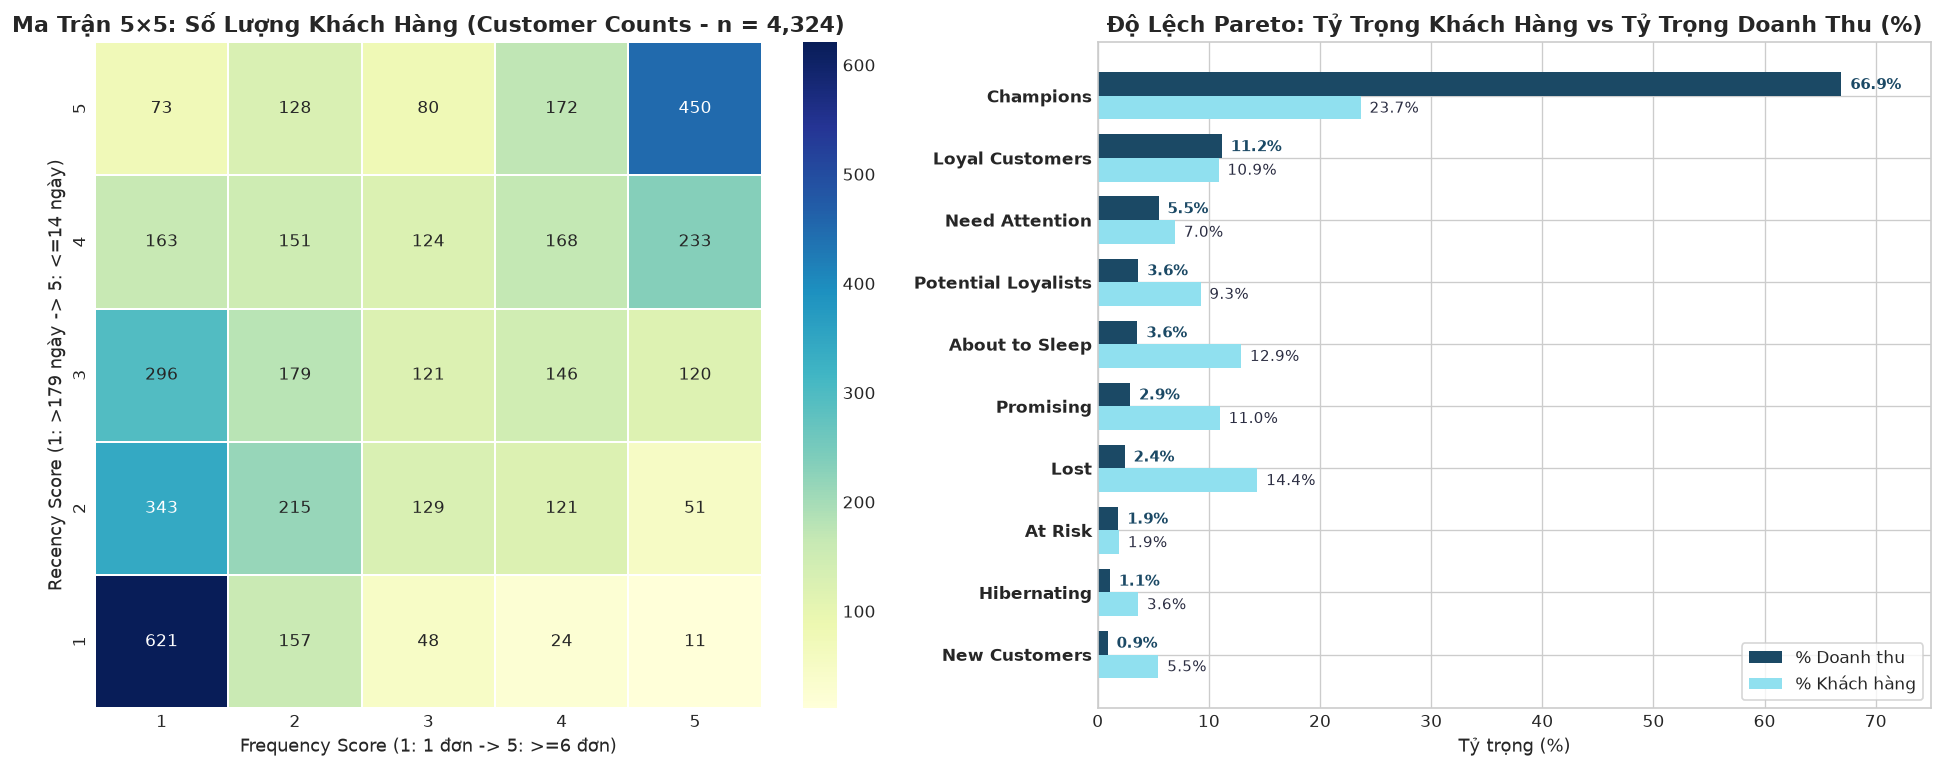

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6.5))

# 1. 5x5 Grid Heatmap (Customer Counts)
grid_counts = rfm.groupby(["R_Score", "F_Score"]).size().unstack(fill_value=0).sort_index(ascending=False)
sns.heatmap(grid_counts, annot=True, fmt=",d", cmap="YlGnBu", cbar=True, ax=ax1, linewidths=1)
ax1.set_title("Ma Trận 5×5: Số Lượng Khách Hàng (Customer Counts - n = 4,324)", fontsize=13, fontweight="bold")
ax1.set_xlabel("Frequency Score (1: 1 đơn -> 5: >=6 đơn)", fontsize=11)
ax1.set_ylabel("Recency Score (1: >179 ngày -> 5: <=14 ngày)", fontsize=11)

# 2. Pareto Analysis: Customer Share vs Revenue Share
segments_plot = seg_summary.sort_values("PctRevenue", ascending=True)
y_positions = np.arange(len(segments_plot))
bar_width = 0.38

ax2.barh(y_positions + bar_width/2, segments_plot["PctRevenue"], height=bar_width, label="% Doanh thu", color="#1b4965")
ax2.barh(y_positions - bar_width/2, segments_plot["PctCustomers"], height=bar_width, label="% Khách hàng", color="#90e0ef")

ax2.set_yticks(y_positions)
ax2.set_yticklabels(segments_plot["Segment"], fontsize=10, fontweight="bold")
ax2.set_xlabel("Tỷ trọng (%)", fontsize=11)
ax2.set_title("Độ Lệch Pareto: Tỷ Trọng Khách Hàng vs Tỷ Trọng Doanh Thu (%)", fontsize=13, fontweight="bold")
ax2.legend(loc="lower right", frameon=True)

# Ghi chú % lên từng thanh
for i, (p_rev, p_cust) in enumerate(zip(segments_plot["PctRevenue"], segments_plot["PctCustomers"])):
    ax2.text(p_rev + 0.8, i + bar_width/2 - 0.08, f"{p_rev:.1f}%", fontsize=9, fontweight="bold", color="#1b4965")
    ax2.text(p_cust + 0.8, i - bar_width/2 - 0.08, f"{p_cust:.1f}%", fontsize=9, color="#2b2d42")

ax2.set_xlim(0, 75)
plt.tight_layout()
plt.show()


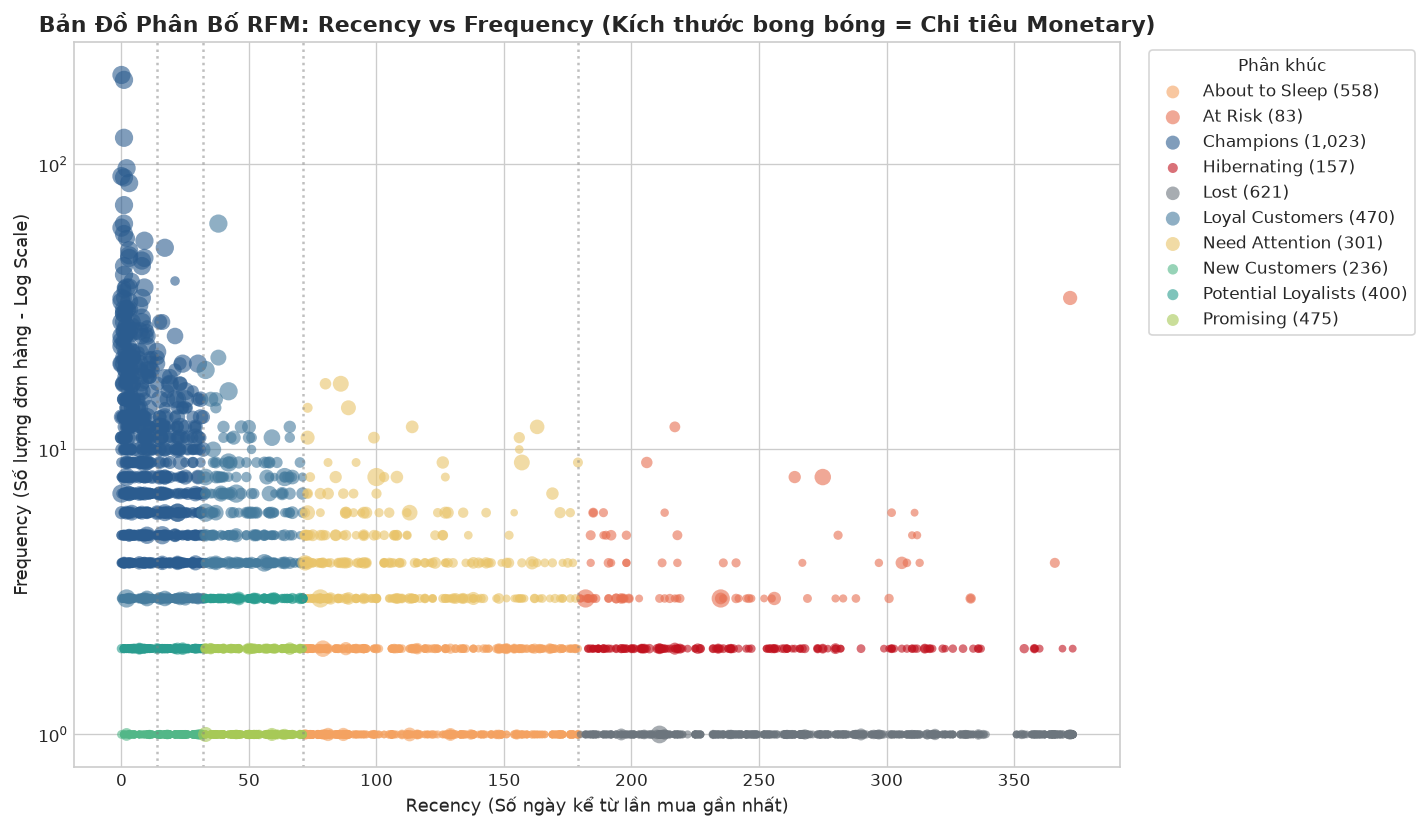

In [8]:
fig, ax = plt.subplots(figsize=(12, 7))

palette = {
    "Champions": "#2b5c8f",
    "Loyal Customers": "#457b9d",
    "Potential Loyalists": "#2a9d8f",
    "New Customers": "#52b788",
    "Promising": "#a7c957",
    "Need Attention": "#e9c46a",
    "About to Sleep": "#f4a261",
    "At Risk": "#e76f51",
    "Hibernating": "#c1121f",
    "Lost": "#6c757d"
}

for seg_name, grp in rfm.groupby("Segment"):
    ax.scatter(
        grp["Recency"],
        grp["Frequency"],
        label=f"{seg_name} ({len(grp):,})",
        color=palette.get(seg_name, "#333333"),
        alpha=0.6,
        s=grp["Monetary"].clip(upper=10000) / 100 + 20,
        edgecolors="none"
    )

ax.set_yscale("log")
ax.set_title("Bản Đồ Phân Bố RFM: Recency vs Frequency (Kích thước bong bóng = Chi tiêu Monetary)", fontsize=13, fontweight="bold")
ax.set_xlabel("Recency (Số ngày kể từ lần mua gần nhất)", fontsize=11)
ax.set_ylabel("Frequency (Số lượng đơn hàng - Log Scale)", fontsize=11)
ax.axvline(14, color="gray", linestyle=":", alpha=0.5)
ax.axvline(32, color="gray", linestyle=":", alpha=0.5)
ax.axvline(71, color="gray", linestyle=":", alpha=0.5)
ax.axvline(179, color="gray", linestyle=":", alpha=0.5)
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", frameon=True, title="Phân khúc")
plt.tight_layout()
plt.show()


## 7. Xuất Dữ Liệu Phân Khúc & Cờ Kỹ Thuật IsZeroNet
Đóng gói toàn bộ 4.334 khách hàng (4.324 Active + 10 Zero Net Spend). Đối với nhóm Zero Net Spend, hệ thống bảo tồn các giá trị hành vi thực tế (`Recency` và `Frequency` thật, tính `R_Score` và `F_Score` thật), đồng thời gắn cờ boolean `IsZeroNet = True` để tránh tính toán nhầm lẫn ở các bước phân tích tiếp theo.


In [9]:
# 1. Chuẩn bị bảng cho 10 khách Zero Net Spend với giá trị hành vi thực tế
zero_recencies = [(ref_date - df_clean[df_clean["CustomerID"] == cid]["InvoiceDate"].max()).days for cid in zero_net_cids]
zero_frequencies = [df_clean[df_clean["CustomerID"] == cid]["InvoiceNo"].nunique() for cid in zero_net_cids]
zero_gross = [df_clean[df_clean["CustomerID"] == cid]["TotalAmount"].sum() for cid in zero_net_cids]
zero_returns = [abs(returns_clean[(returns_clean["CustomerID"] == cid) & (returns_clean["IsMatched"])]["ReturnAmount"].sum()) for cid in zero_net_cids]

# Tính R_Score và F_Score thật cho khách Zero Net theo cùng các ngưỡng phân vị
zero_r_scores = pd.cut(zero_recencies, bins=[-np.inf, q_recency[0.2], q_recency[0.4], q_recency[0.6], q_recency[0.8], np.inf], labels=[5, 4, 3, 2, 1]).astype(int)
zero_f_scores = pd.cut(zero_frequencies, bins=[0, 1, 2, 3, 5, np.inf], labels=[1, 2, 3, 4, 5]).astype(int)

df_zero_export = pd.DataFrame({
    "CustomerID": zero_net_cids,
    "Recency": zero_recencies,
    "Frequency": zero_frequencies,
    "GrossSpend": zero_gross,
    "MatchedReturnSpend": zero_returns,
    "Monetary": [0.0] * len(zero_net_cids),
    "R_Score": zero_r_scores,
    "F_Score": zero_f_scores,
    "M_Score": [0] * len(zero_net_cids),
    "RFM_Code": [None] * len(zero_net_cids),
    "Segment": ["Zero Net Spend"] * len(zero_net_cids),
    "IsZeroNet": [True] * len(zero_net_cids)
})

# 2. Gắn cờ IsZeroNet = False cho nhóm Active
rfm["IsZeroNet"] = False

# 3. Hợp nhất tập Active và Zero Net
rfm_final_export = pd.concat([rfm, df_zero_export], ignore_index=True)

# 4. Xuất file parquet và csv
export_parquet = "../data/processed/rfm_segmented.parquet"
export_csv = "../data/processed/rfm_segmented.csv"

rfm_final_export.to_parquet(export_parquet, index=False)
rfm_final_export.to_csv(export_csv, index=False)

print(f"Đã xuất thành công tệp: {export_parquet} và {export_csv}")

# 5. Kiểm định độc lập tệp vừa xuất (Invariant Testing)
exported_df = pd.read_parquet(export_parquet)
print(f"Số dòng xuất: {len(exported_df):,} dòng")
print(f"Số khách Zero Net: {exported_df['IsZeroNet'].sum():,} khách")
print(f"Số khách Active: {(~exported_df['IsZeroNet']).sum():,} khách")

assert len(exported_df) == 4334, "Kỳ vọng 4,334 khách hàng"
assert exported_df["IsZeroNet"].sum() == 10, "Kỳ vọng đúng 10 khách Zero Net Spend"
assert (~exported_df["IsZeroNet"]).sum() == 4324, "Kỳ vọng đúng 4,324 khách Active"
assert round(exported_df["Monetary"].sum(), 2) == 8287643.12, "Tổng Monetary bị lệch!"
assert (exported_df[exported_df["IsZeroNet"]]["Monetary"] == 0.0).all(), "Toàn bộ khách Zero Net phải có Monetary = 0.0"
assert (exported_df[~exported_df["IsZeroNet"]]["Monetary"] >= 0.01).all(), "Toàn bộ khách Active phải có Monetary >= 0.01"

print("TẤT CẢ KIỂM ĐỊNH BẤT BIẾN SAU XUẤT ĐỀU ĐẠT CHUẨN 100%!")


Đã xuất thành công tệp: ../data/processed/rfm_segmented.parquet và ../data/processed/rfm_segmented.csv
Số dòng xuất: 4,334 dòng
Số khách Zero Net: 10 khách
Số khách Active: 4,324 khách
TẤT CẢ KIỂM ĐỊNH BẤT BIẾN SAU XUẤT ĐỀU ĐẠT CHUẨN 100%!


## 8. Kết Luận Cốt Lõi Về Phân Khúc Khách Hàng (Chuyển Tiếp Sang Notebook 04)
1. **Sự tập trung doanh thu cực độ (Extreme Pareto Concentration):**
   * Phân khúc **Champions** chiếm **23,7% số lượng khách** (1.023 khách) nhưng nắm giữ tới **66,9% tổng doanh thu** (£5,55 triệu), với mức chi tiêu trung bình lên đến £5.421/khách và tần suất trung bình 10,7 đơn.
   * **Định hướng chiến lược:** Đây là "bầu sữa" sống còn của mô hình kinh doanh sỉ (B2B Wholesale). Doanh nghiệp bắt buộc phải có chính sách Quản trị khách hàng trọng điểm (Key Account Management - KAM) với hạn mức tín dụng và chiết khấu linh hoạt để bảo vệ tối đa tệp này.
2. **Vai trò cầu nối của phân khúc Promising (Tiềm năng phát triển):**
   * Chiếm **11,0% khách hàng** (475 khách) với 1–2 đơn hàng phát sinh trong vòng 30 – 70 ngày gần nhất.
   * **Định hướng chiến lược:** Đây là tệp "bản lề" có tiềm năng chuyển hóa thành khách trung thành cao nhất. Cần ưu tiên các chiến dịch chăm sóc và nhắc đơn tự động (Automated Nudge) nhằm kích hoạt đơn hàng thứ hai/thứ ba trước khi họ trôi dạt vào vùng nguội lạnh (*About to Sleep* hoặc *Lost*).
3. **Quy mô tệp rủi ro rời bỏ cần can thiệp:**
   * Tệp **Need Attention** (301 khách, 5,5% doanh thu) và **At Risk** (83 khách, 1,9% doanh thu) từng có tần suất mua lớn nhưng đang có dấu hiệu ngừng giao dịch dài ngày.
   * **Định hướng chiến lược:** Đây là nhóm mục tiêu cho các chương trình kích hoạt lại (Re-activation). Notebook 04 sẽ thiết kế bài toán thử nghiệm A/B Testing có nhóm đối chứng để đo lường hiệu quả tăng thêm thực tế và tối ưu hóa chi phí ưu đãi.
